# Analysis


In [1]:

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import math
from pathlib import Path
from collections import OrderedDict

In [2]:
from pathlib import Path
rootDir = Path.cwd()

In [3]:
rootDir = "/content/drive/MyDrive/Paper3/HallucinationTaxonomy"

# Charts


In [6]:

MAPPING = OrderedDict({
    "Prompt Faithfulness": OrderedDict([
        ("A1", "Unsupported Entity"),
        ("A2", "Unsupported Relation"),
        ("A3", "Over-specific Detail"),
        ("A4", "Missed Requirement"),
    ]),
    "Code Faithfulness": OrderedDict([
        ("B1", "Dropped Step"),
        ("B2", "Fabricated Code"),
        ("B3", "Contradiction"),
        ("B4", "Structural Mismatch"),
    ]),
    "Reasoning Quality": OrderedDict([
        ("C1", "Speculative Branch"),
        ("C2", "Goal Drift"),
        ("C3", "Tool Misuse"),
    ]),
})

BASE_COLORS = {
    "Prompt Faithfulness": "#1E91D6",
    "Code Faithfulness": "#7C4DFF",
    "Reasoning Quality": "#F39C12",
}


def read_csv_safely(path):
    try:
        return pd.read_csv(path, encoding="utf-8-sig")
    except UnicodeDecodeError:
        return pd.read_csv(path, encoding="cp1252")


def lighten(hex_color, factor=0.35):
    h = hex_color.lstrip("#")
    rgb = [int(h[i:i+2], 16) / 255 for i in (0, 2, 4)]
    return tuple(c + (1 - c) * factor for c in rgb)


def create_donut_chart(
    prompt_file,
    code_file,
    reasoning_file,
    dataset_name="Dataset"
    ):

    lens_files = {
        "Prompt Faithfulness": prompt_file,
        "Code Faithfulness": code_file,
        "Reasoning Quality": reasoning_file,
    }

    data = OrderedDict()

    # 1. Read and validate data
    for dimension, code_map in MAPPING.items():

        df = read_csv_safely(lens_files[dimension])

        if "subcategory" not in df.columns:
            raise ValueError(
                f"Missing 'subcategory' column: {lens_files[dimension]}"
            )

        codes = (
            df["subcategory"]
            .dropna()
            .astype(str)
            .str.strip()
            .str.upper()
        )

        codes = codes[codes != ""]
        counts = codes.value_counts().to_dict()

        unknown = set(counts) - set(code_map)

        if unknown:
            raise ValueError(
                f"{dimension}: Unknown codes {sorted(unknown)} "
                f"in {lens_files[dimension]}"
            )

        data[dimension] = OrderedDict(
            (name, int(counts.get(code, 0)))
            for code, name in code_map.items()
        )

    # 2. Prepare chart data
    outer_labels = []
    outer_vals = []
    outer_parents = []


    for dimension, subtypes in data.items():
        for subtype, count in subtypes.items():
          if count == 0:
            continue
          outer_labels.append(subtype)
          outer_vals.append(count)
          outer_parents.append(dimension)


    inner_labels = list(data.keys())
    inner_vals = [
        sum(subtypes.values())
        for subtypes in data.values()
    ]

    total = sum(outer_vals)

    if total == 0:
        raise ValueError("No hallucination annotations found.")

    inner_pct = [100 * v / total for v in inner_vals]
    outer_pct = [100 * v / total for v in outer_vals]

    # 3. Print frequencies
    print(f"\n{dataset_name}")
    print(f"Total hallucinations: {total}\n")

    for dimension, subtypes in data.items():
        dim_total = sum(subtypes.values())
        print(
            f"{dimension}: {dim_total} "
            f"({100 * dim_total / total:.2f}%)"
        )

        for subtype, count in subtypes.items():
            print(
                f"  {subtype}: {count} "
                f"({100 * count / total:.2f}%)"
            )

    # 4. Chart style
    with mpl.rc_context({
        "figure.dpi": 300,
        "savefig.dpi": 300,
        "font.family": "DejaVu Sans",
        "font.size": 9,
        "axes.facecolor": "white",
        "figure.facecolor": "white",
        "text.color": "#2A2A2A",
    }):

        inner_colors = [
            (*mpl.colors.to_rgb(BASE_COLORS[cat]), 0.90)
            for cat in inner_labels
        ]

        outer_colors = [
            (*lighten(BASE_COLORS[parent]), 0.75)
            for parent in outer_parents
        ]

        fig, ax = plt.subplots(figsize=(9, 9))

        # Inner ring
        wedges_inner, _ = ax.pie(
            inner_vals,
            radius=1.0,
            startangle=90,
            counterclock=False,
            colors=inner_colors,
            wedgeprops=dict(
                width=0.35,
                edgecolor="white",
                linewidth=1,
                antialiased=True
            )
        )

        # Outer ring
        wedges_outer, _ = ax.pie(
            outer_vals,
            radius=1.35,
            startangle=90,
            counterclock=False,
            colors=outer_colors,
            wedgeprops=dict(
                width=0.35,
                edgecolor="white",
                linewidth=1,
                antialiased=True
            )
        )

        ax.set(aspect="equal")

        # Inner labels
        for wedge, category, percentage in zip(
            wedges_inner, inner_labels, inner_pct
        ):
            angle = (wedge.theta1 + wedge.theta2) / 2
            radius = 1.0 - 0.35 / 2

            x = radius * math.cos(math.radians(angle))
            y = radius * math.sin(math.radians(angle))

            ax.text(
                x, y,
                f"{category}\n({percentage:.2f}%)",
                ha="center",
                va="center",
                fontsize=9,
                fontweight="semibold"
            )

        # Outer labels
        outer_radius = 1.35
        label_offset = 0.18

        for wedge, label, percentage in zip(
            wedges_outer, outer_labels, outer_pct
        ):
            angle = (wedge.theta1 + wedge.theta2) / 2
            radians = math.radians(angle)

            x0 = outer_radius * math.cos(radians)
            y0 = outer_radius * math.sin(radians)

            label_radius = outer_radius + label_offset

            lx = label_radius * math.cos(radians)
            ly = label_radius * math.sin(radians)

            alignment = "left" if lx >= 0 else "right"

            ax.annotate(
                "",
                xy=(lx, ly),
                xytext=(x0, y0),
                annotation_clip=False,
                arrowprops=dict(
                    arrowstyle="-",
                    color="#5A5A5A",
                    lw=1.0,
                    shrinkA=0,
                    shrinkB=0,
                    connectionstyle="arc3",
                    alpha=0.9
                ),
                zorder=10
            )

            ax.text(
                lx, ly,
                f"{label} ({percentage:.2f}%)",
                ha=alignment,
                va="center",
                fontsize=10.5,
                zorder=11
            )

        ax.add_artist(
            plt.Circle(
                (0, 0), 1.0,
                fill=False,
                linewidth=0.8,
                edgecolor="#DDDDDD"
            )
        )

        ax.add_artist(
            plt.Circle(
                (0, 0), 1.35,
                fill=False,
                linewidth=0.8,
                edgecolor="#DDDDDD"
            )
        )

        plt.tight_layout(pad=1.0)

        png_path = f"{rootDir}/Figures/{dataset_name}_donut.png"
        svg_path = f"{rootDir}/Figures/{dataset_name}_donut.svg"

        fig.savefig(png_path, bbox_inches="tight", transparent=True)
        fig.savefig(svg_path, bbox_inches="tight", transparent=True)

        print(f"\nSaved: {png_path}")
        print(f"Saved: {svg_path}")

        plt.show()
        plt.close(fig)

    return data



DS1
Total hallucinations: 421

Prompt Faithfulness: 130 (30.88%)
  Unsupported Entity: 26 (6.18%)
  Unsupported Relation: 23 (5.46%)
  Over-specific Detail: 63 (14.96%)
  Missed Requirement: 18 (4.28%)
Code Faithfulness: 203 (48.22%)
  Dropped Step: 39 (9.26%)
  Fabricated Code: 59 (14.01%)
  Contradiction: 84 (19.95%)
  Structural Mismatch: 21 (4.99%)
Reasoning Quality: 88 (20.90%)
  Speculative Branch: 19 (4.51%)
  Goal Drift: 14 (3.33%)
  Tool Misuse: 55 (13.06%)

Saved: /content/drive/MyDrive/Paper3/HallucinationTaxonomy/Figures/DS1_donut.png
Saved: /content/drive/MyDrive/Paper3/HallucinationTaxonomy/Figures/DS1_donut.svg


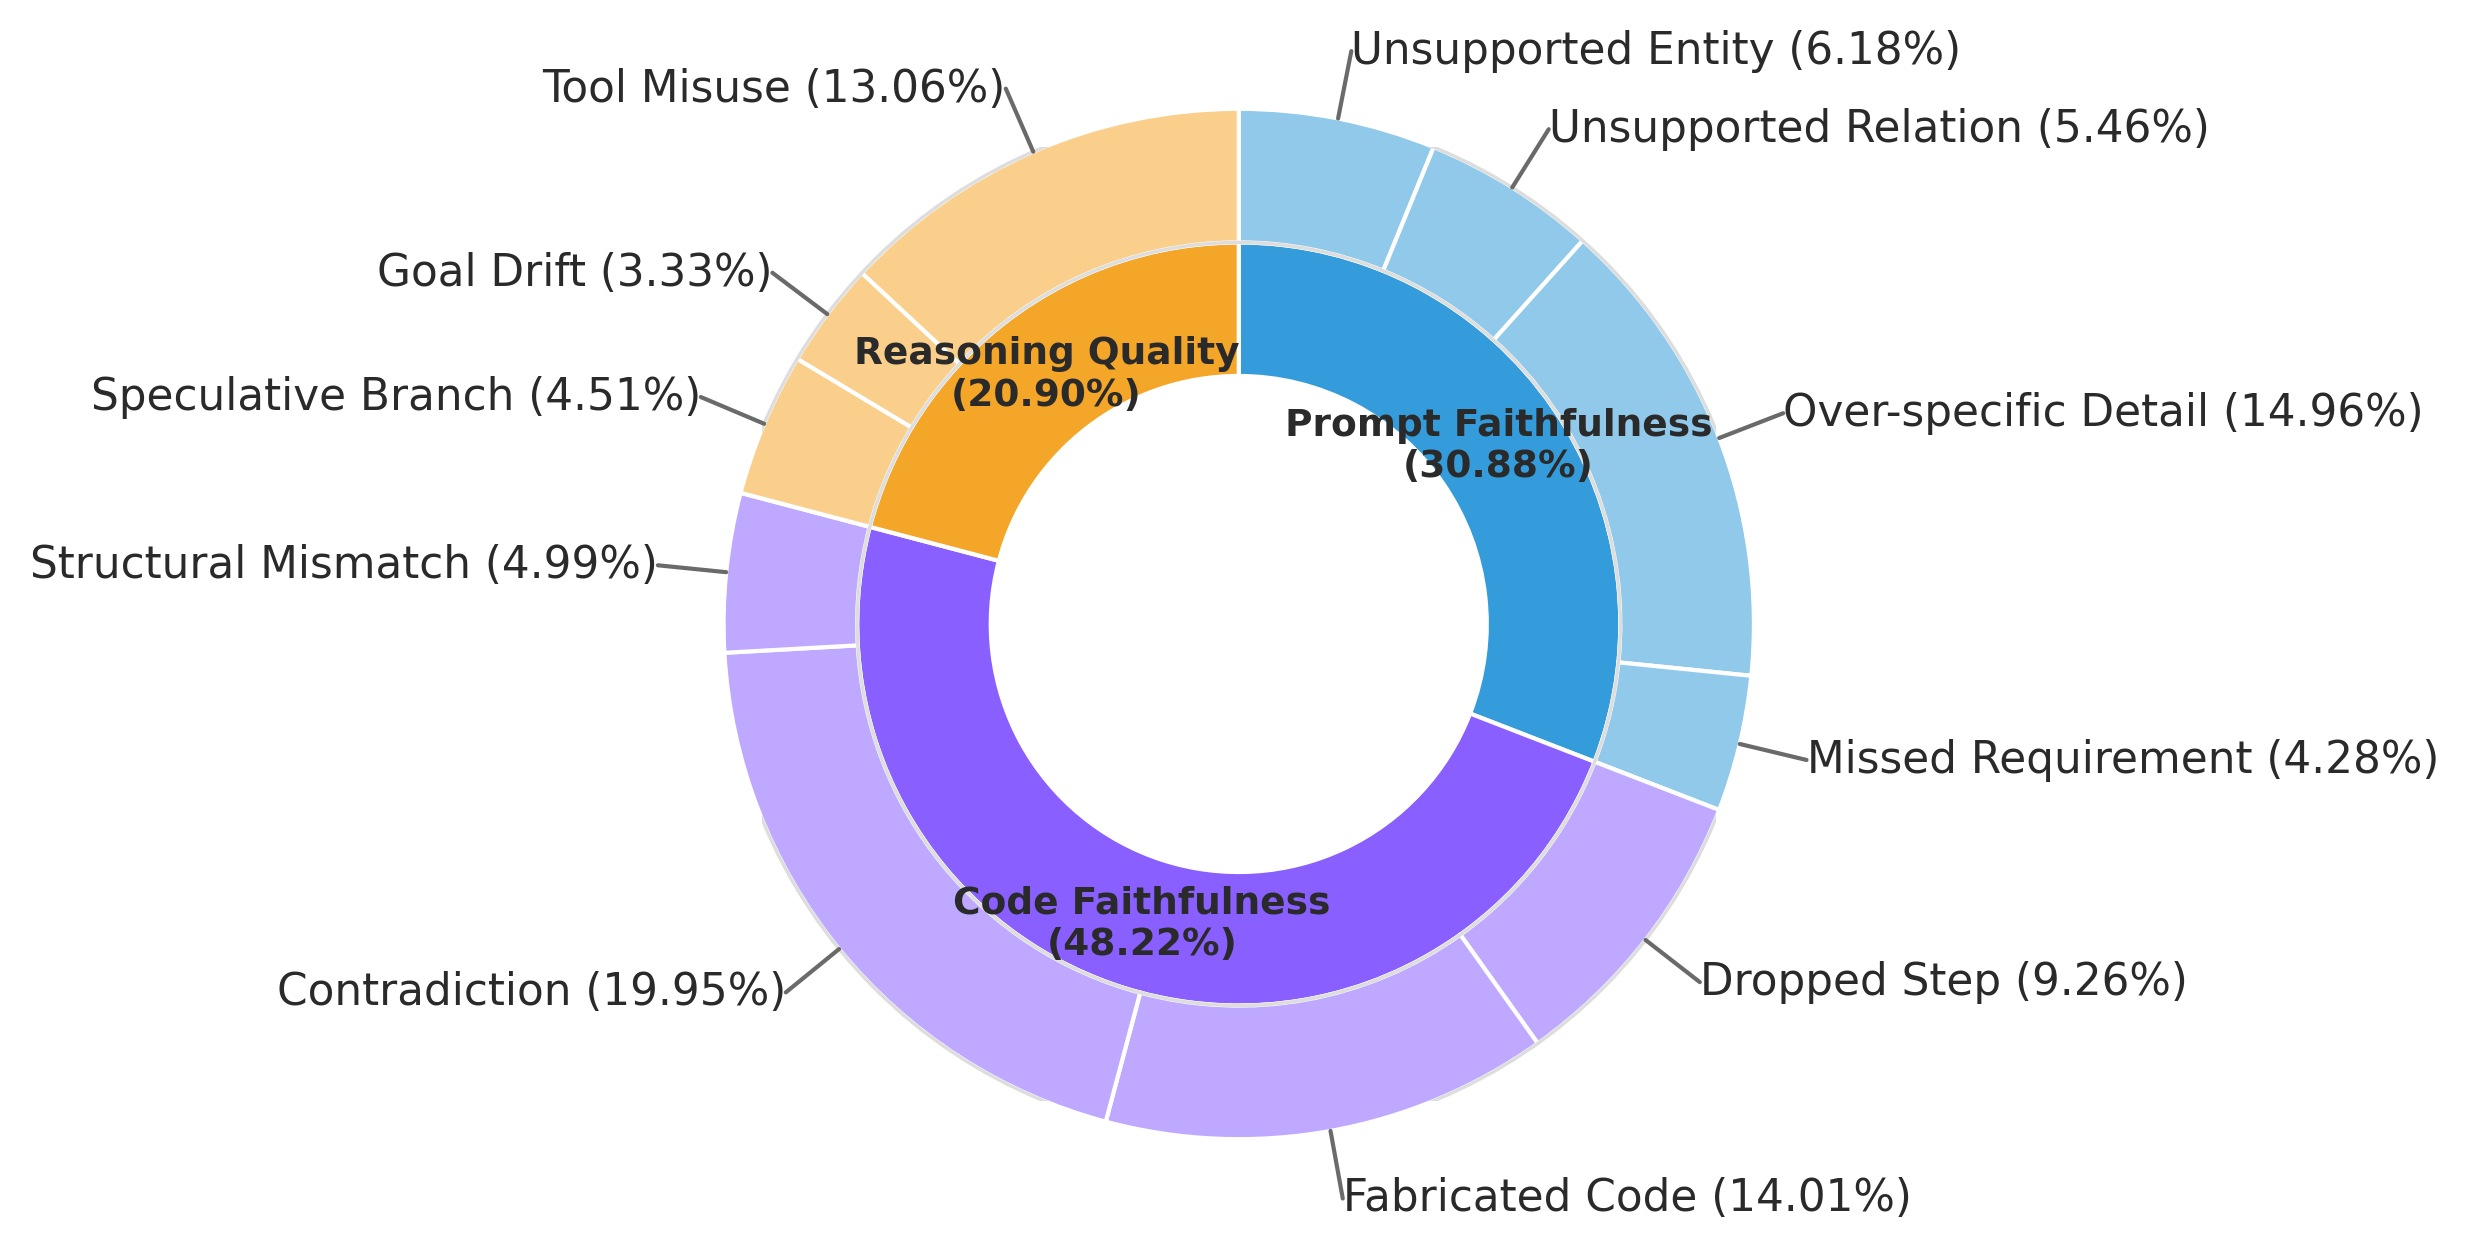

In [9]:
PromptFaithfulness = f"{rootDir}/Result/Dataset1/PromptFaitfulness.csv"   # A1–A4 errors
CodeFaithfulness =    f"{rootDir}/Result/Dataset1/CodeFaithfulness.csv"   # B1–B5 errors
ReasoningQuality = f"{rootDir}/Result/Dataset1/ReasoningQuality.csv"  # C1–C4 errors
data_ds1 = create_donut_chart(
    PromptFaithfulness,
    CodeFaithfulness,
    ReasoningQuality,
    dataset_name="DS1"
)

In [10]:
#Dataset2
import pandas as pd

base = f"{rootDir}/Result/Dataset2/"

# Prompt Faithfulness
prompt = pd.concat([
    pd.read_csv(f"{base}SecondDSPromptFaitfulnessPart{i}.csv")
    for i in range(1, 5)
], ignore_index=True)

# Code Faithfulness
code = pd.concat([
    pd.read_csv(f"{base}SecondDSCodeFaitfulnessPart{i}.csv")
    for i in range(1, 5)
], ignore_index=True)

# Reasoning Quality
reasoning = pd.concat([
    pd.read_csv(f"{base}SecondDSReasoningQualityPart{i}.csv")
    for i in range(1, 5)
], ignore_index=True)

# Save merged files
prompt.to_csv(f"{base}PromptMerged.csv", index=False)
code.to_csv(f"{base}CodeMerged.csv", index=False)
reasoning.to_csv(f"{base}ReasoningMerged.csv", index=False)


DS2
Total hallucinations: 1367

Prompt Faithfulness: 506 (37.02%)
  Unsupported Entity: 209 (15.29%)
  Unsupported Relation: 3 (0.22%)
  Over-specific Detail: 237 (17.34%)
  Missed Requirement: 57 (4.17%)
Code Faithfulness: 570 (41.70%)
  Dropped Step: 154 (11.27%)
  Fabricated Code: 220 (16.09%)
  Contradiction: 176 (12.87%)
  Structural Mismatch: 20 (1.46%)
Reasoning Quality: 291 (21.29%)
  Speculative Branch: 192 (14.05%)
  Goal Drift: 7 (0.51%)
  Tool Misuse: 92 (6.73%)

Saved: /content/drive/MyDrive/Paper3/HallucinationTaxonomy/Figures/DS2_donut.png
Saved: /content/drive/MyDrive/Paper3/HallucinationTaxonomy/Figures/DS2_donut.svg


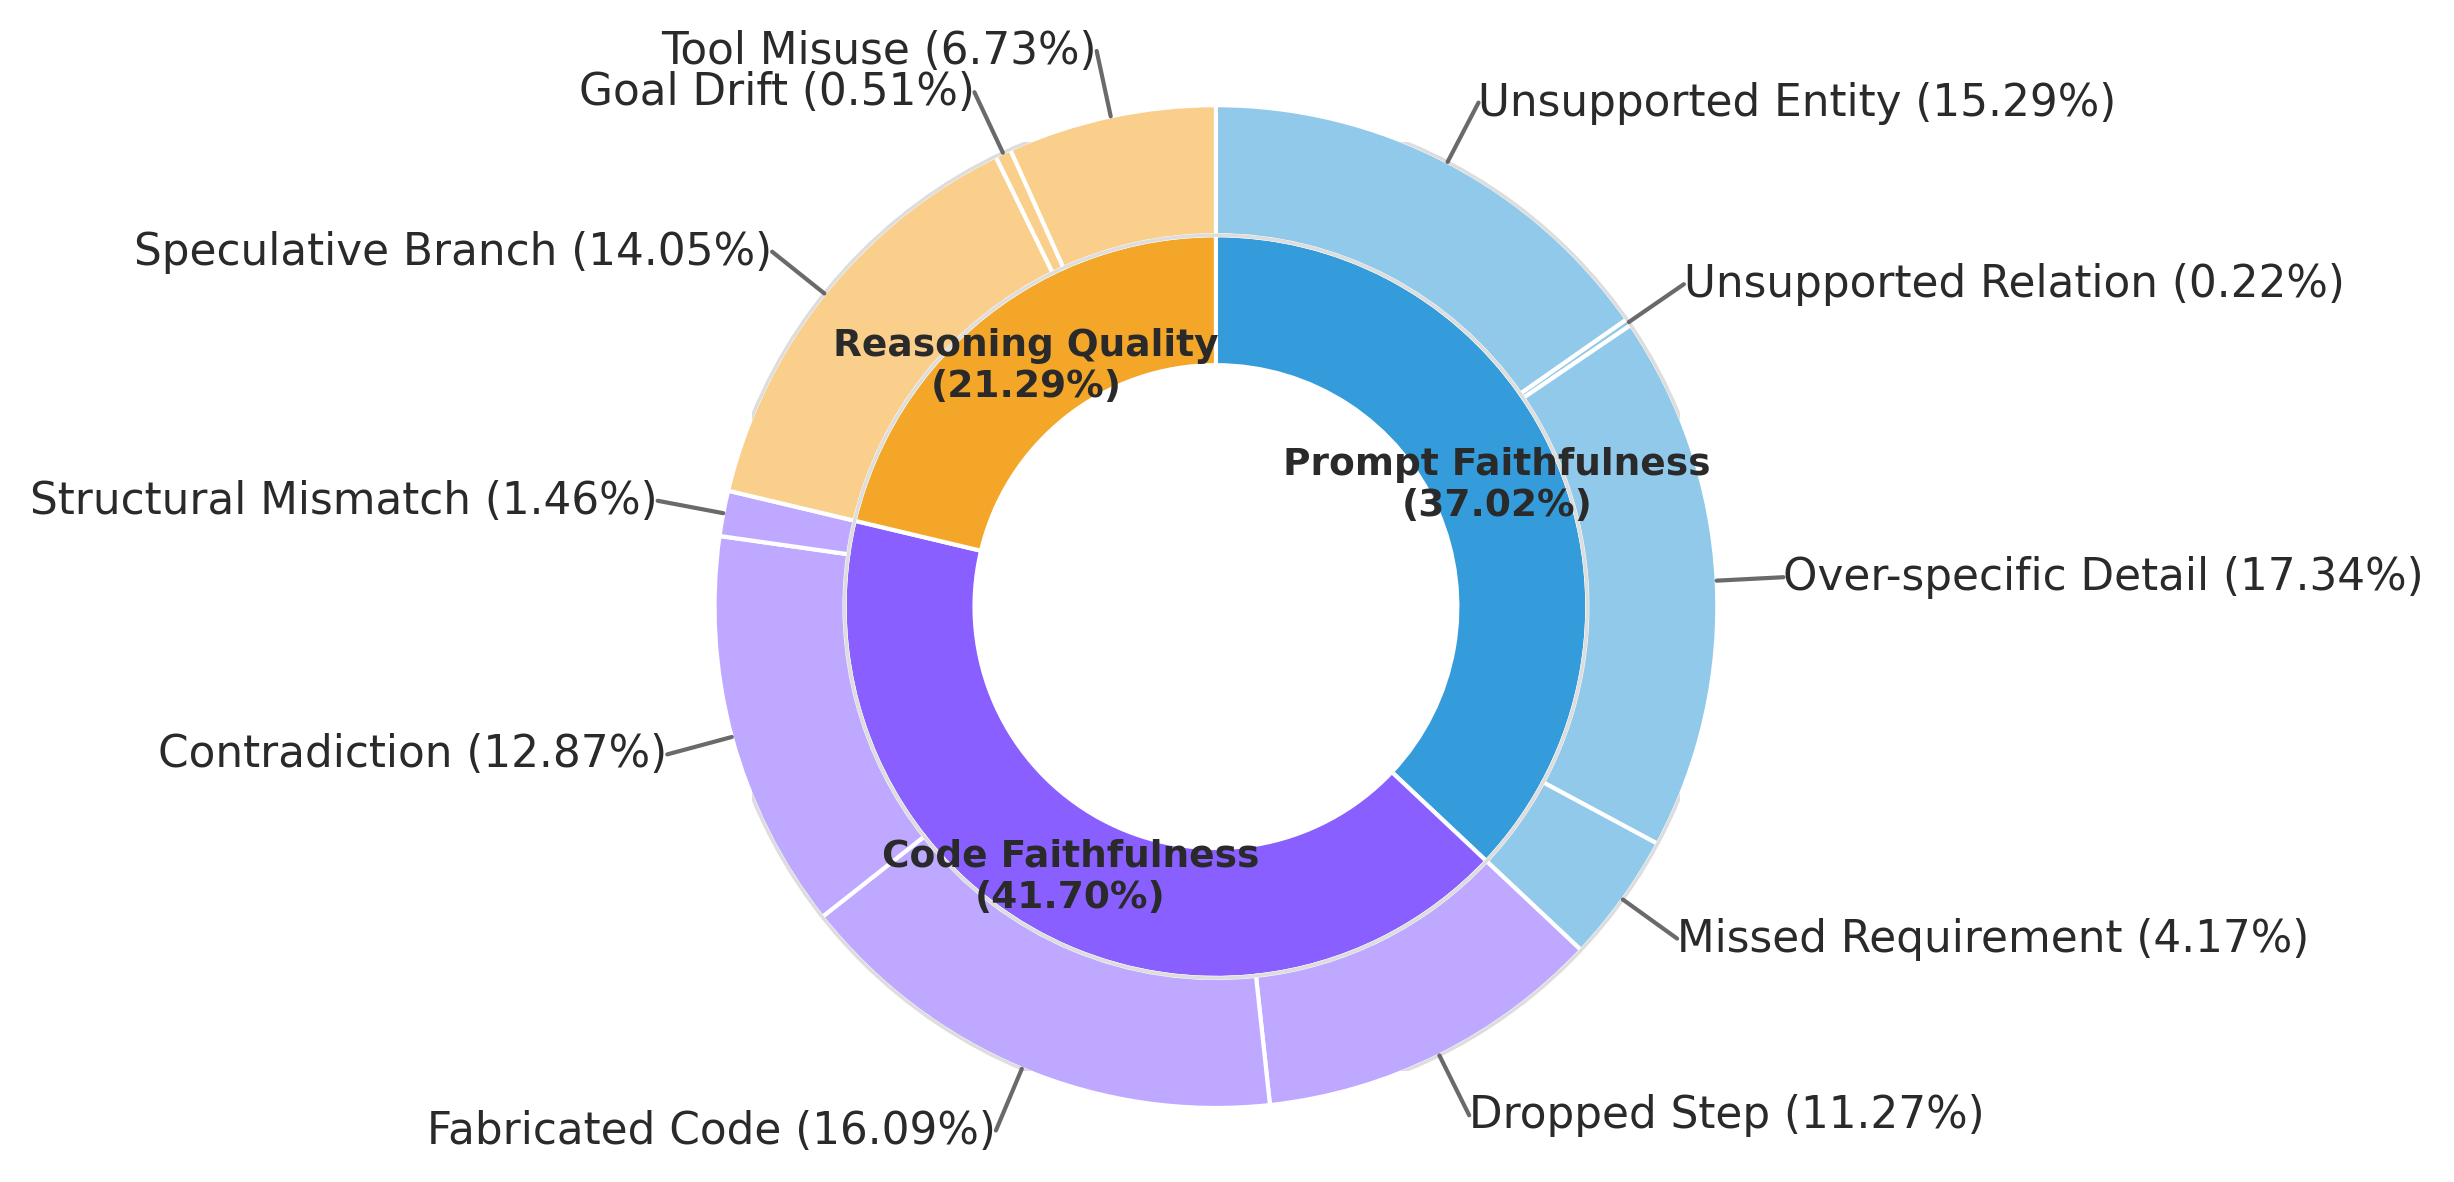

In [11]:
PromptFaithfulness =f"{base}PromptMerged.csv"
CodeFaithfulness =    f"{base}CodeMerged.csv"
ReasoningQuality = f"{base}ReasoningMerged.csv"
data_ds1 = create_donut_chart(
    PromptFaithfulness,
    CodeFaithfulness,
    ReasoningQuality,
    dataset_name="DS2"
)


DS1-V4
Total hallucinations: 104

Prompt Faithfulness: 59 (56.73%)
  Unsupported Entity: 16 (15.38%)
  Unsupported Relation: 21 (20.19%)
  Over-specific Detail: 20 (19.23%)
  Missed Requirement: 2 (1.92%)
Code Faithfulness: 6 (5.77%)
  Dropped Step: 0 (0.00%)
  Fabricated Code: 0 (0.00%)
  Contradiction: 6 (5.77%)
  Structural Mismatch: 0 (0.00%)
Reasoning Quality: 39 (37.50%)
  Speculative Branch: 16 (15.38%)
  Goal Drift: 5 (4.81%)
  Tool Misuse: 18 (17.31%)

Saved: /content/drive/MyDrive/Paper3/HallucinationTaxonomy/Figures/DS1-V4_donut.png
Saved: /content/drive/MyDrive/Paper3/HallucinationTaxonomy/Figures/DS1-V4_donut.svg


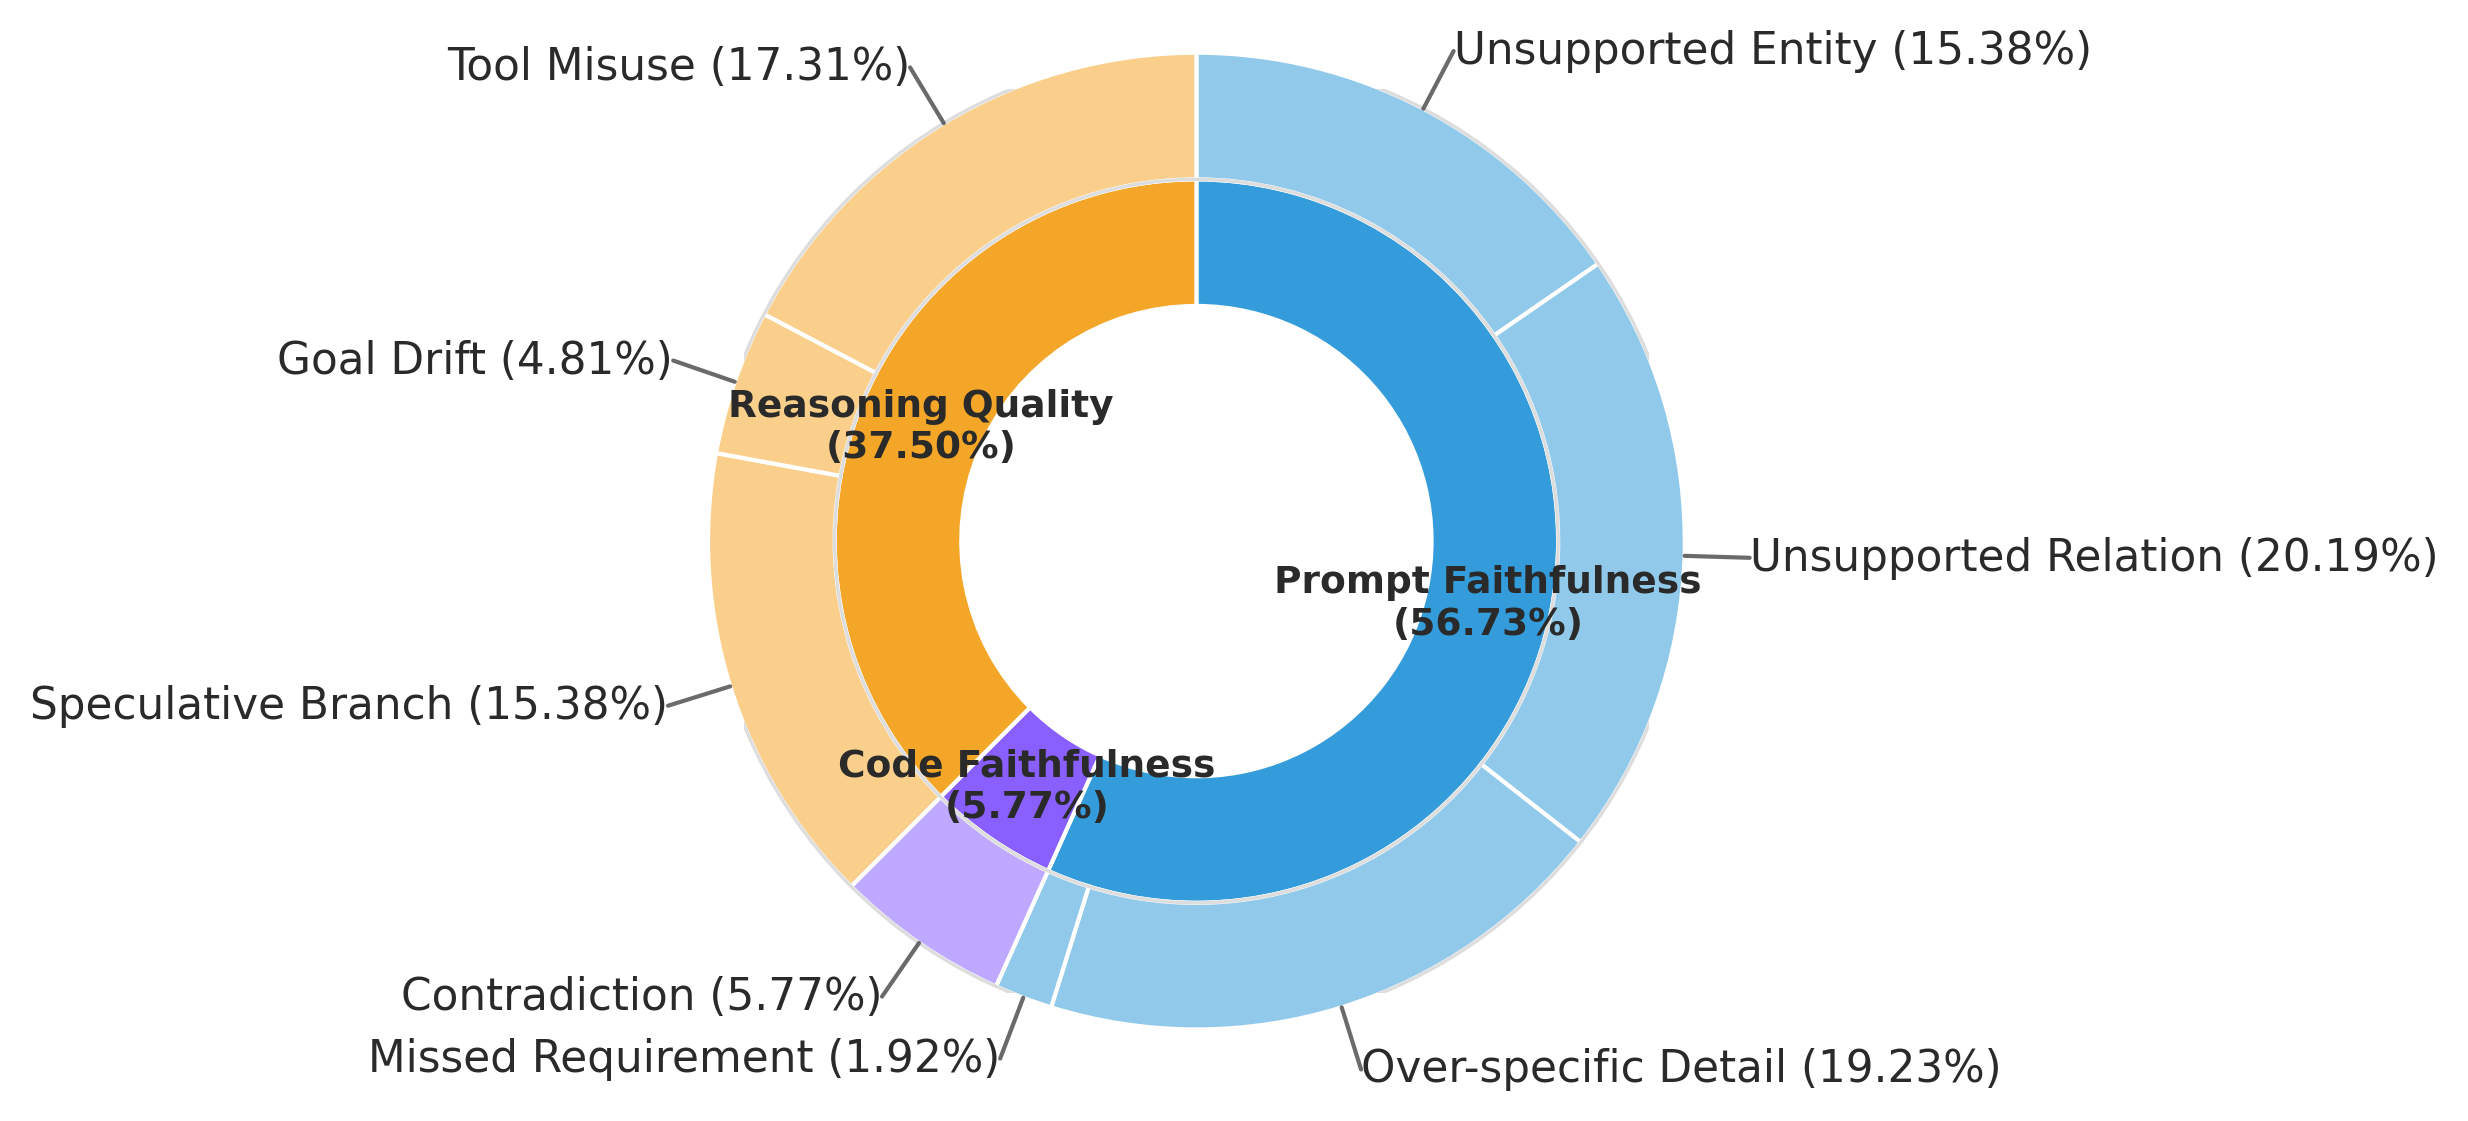

In [12]:
#DataSet1 with DeepseekV4-Pro
PromptFaithfulness = f"{rootDir}/Result/Dataset1-DeepSeek-V4/PromptFaitfulnessV4.csv"
CodeFaithfulness =    f"{rootDir}/Result/Dataset1-DeepSeek-V4/CodeFaithfulnessV4.csv"
ReasoningQuality = f"{rootDir}/Result/Dataset1-DeepSeek-V4/ReasoningQualityV4.csv"
data_ds1 = create_donut_chart(
    PromptFaithfulness,
    CodeFaithfulness,
    ReasoningQuality,
    dataset_name="DS1-V4"
)


**Agreement**

In [4]:

import pandas as pd
import numpy as np

def calculate_agreement(
    prompt_file,
    code_file,
    reasoning_file,
    dataset_name="Dataset",
    rater1_col="Rater1",
    rater2_col="Rater2"
):
    files = {
        "Prompt Faithfulness": prompt_file,
        "Code Faithfulness": code_file,
        "Reasoning Quality": reasoning_file
    }

    results = []
    all_data = []

    def load_file(path):
        if str(path).lower().endswith(".csv"):
            return read_csv_safely(path)
        elif str(path).lower().endswith((".xlsx", ".xls")):
            return pd.read_excel(path)
        else:
            raise ValueError(f"Unsupported file format: {path}")

    def compute_metrics(df, lens):
        r1 = df[rater1_col]
        r2 = df[rater2_col]

        TT = ((r1 == "T") & (r2 == "T")).sum()
        TF = ((r1 == "T") & (r2 == "F")).sum()
        FT = ((r1 == "F") & (r2 == "T")).sum()
        FF = ((r1 == "F") & (r2 == "F")).sum()

        union = TT + TF + FT

        # Pairwise F1 (Dice coefficient)
        pairwise_f1 = (
            2 * TT / (2 * TT + TF + FT)
            if union else np.nan
        )

        # Jaccard (Intersection over Union)
        jaccard = TT / union if union else np.nan

        return {
            "Dataset": dataset_name,
            "Lens": lens,
            "N": int(union),
            "TT": int(TT),
            "TF": int(TF),
            "FT": int(FT),
            "Pairwise F1 (%)": round(pairwise_f1 * 100, 2),
            "Jaccard (%)": round(jaccard * 100, 2)
        }

    for lens, path in files.items():
        df = load_file(path)

        required = [rater1_col, rater2_col]
        missing = [c for c in required if c not in df.columns]

        if missing:
            raise ValueError(f"Missing columns in {path}: {missing}")

        for col in required:
            df[col] = (
                df[col]
                .astype("string")
                .str.strip()
                .str.upper()
            )

            if not df[col].isin(["T", "F"]).all():
                raise ValueError(
                    f"Invalid T/F values in {path}, column {col}"
                )

        # Verify union-only annotation data
        both_false = (
            (df[rater1_col] == "F") &
            (df[rater2_col] == "F")
        )

        if both_false.any():
            raise ValueError(
                f"{path}: FF rows found. "
                "Expected union-only annotation data."
            )

        results.append(compute_metrics(df, lens))
        all_data.append(df)

    combined = pd.concat(all_data, ignore_index=True)
    results.append(compute_metrics(combined, "Overall"))

    return pd.DataFrame(results)


In [8]:
dataset1 = calculate_agreement(
    f"{rootDir}/Result/Dataset1/AgreementL1.csv",
    f"{rootDir}/Result/Dataset1/AgreementL2.csv",
    f"{rootDir}/Result/Dataset1/AgreementL3.csv",
    dataset_name="Dataset 1",
    rater1_col="Rater1",
    rater2_col="Rater2"
)


display(dataset1)

,Dataset,Lens,N,TT,TF,FT,Pairwise F1 (%),Jaccard (%)
0,Dataset 1,Prompt Faithfulness,107,71,25,11,79.78,66.36
1,Dataset 1,Code Faithfulness,160,142,11,7,94.04,88.75
2,Dataset 1,Reasoning Quality,116,52,47,17,61.90,44.83
3,Dataset 1,Overall,383,265,83,35,81.79,69.19


In [27]:
#DataSet2
dataset2 = calculate_agreement(
    f"{rootDir}/Result/Dataset2/SecondDSAgreementL1.csv",
   f"{rootDir}/Result/Dataset2/SecondDSAgreementL2.csv",
    f"{rootDir}/Result/Dataset2/SecondDSAgreementL3.csv",
    dataset_name="Dataset 2",
    rater1_col="Rater1",
    rater2_col="Rater2"
)
display(dataset2)

,Dataset,Lens,N,TT,TF,FT,Pairwise F1 (%),Jaccard (%)
0,Dataset 1,Prompt Faithfulness,130,83,42,5,77.93,63.85
1,Dataset 1,Code Faithfulness,145,113,28,4,87.60,77.93
2,Dataset 1,Reasoning Quality,74,51,23,0,81.60,68.92
3,Dataset 1,Overall,349,247,93,9,82.89,70.77
